Цена входа p0:  $2982.81
ETH0:           0.3353 ETH
USD0:           $1000.00
Liquidity liq:  18.3100

ГИПОТЕЗА 1.2: LP Returns vs Arbitrage Activity
Pearson r:     -0.5738
P-value:       0.0000
Значима:       ДА ✓
Направление:   Отрицательная ✓


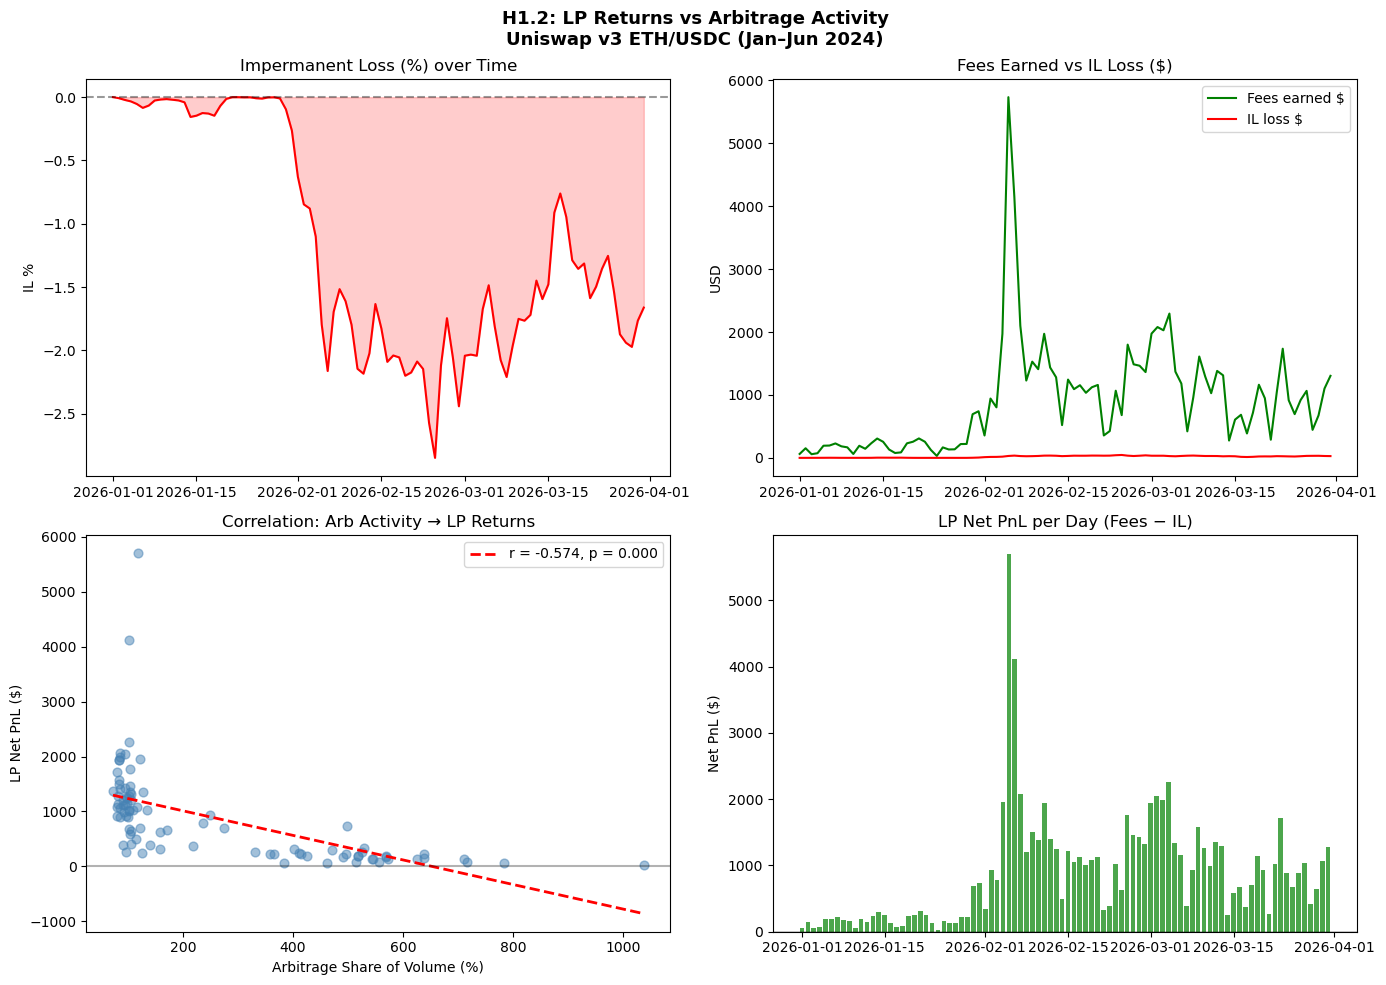

In [2]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import os
# ============================================================
# 1. ЗАГРУЗКА ДАННЫХ
# ============================================================

swaps = pd.read_csv('/Users/aleksandra/Desktop/newdata/swaps_daily.csv', parse_dates=['day'])
arb   = pd.read_csv('/Users/aleksandra/Desktop/newdata/arb_daily.csv',   parse_dates=['day'])
price = pd.read_csv('/Users/aleksandra/Desktop/newdata/eth_price.csv',   parse_dates=['day'])

# Объединяем всё в один датафрейм
df = swaps.merge(arb,   on='day', how='left')
df = df.merge(price, on='day', how='left')
df = df.fillna(0)
df = df.sort_values('day').reset_index(drop=True)

# ============================================================
# 2. ПАРАМЕТРЫ LP-ПОЗИЦИИ (задаёшь один раз)
# ============================================================
p0   = df['eth_price_usd'].iloc[0]   # цена входа
USD0 = 1000                           # вложили $1000 USDC
ETH0 = USD0 / p0                      # вложили ETH на эту же сумму
liq  = np.sqrt(USD0 * ETH0)           # константа ликвидности

print(f"Цена входа p0:  ${p0:.2f}")
print(f"ETH0:           {ETH0:.4f} ETH")
print(f"USD0:           ${USD0:.2f}")
print(f"Liquidity liq:  {liq:.4f}")

# ============================================================
# 3. РАСЧЁТ IL ПО ТВОИМ ФОРМУЛАМ
# ============================================================
df['LpVal'] = 2 * liq * np.sqrt(df['eth_price_usd'])
df['HODL']  = USD0 + ETH0 * df['eth_price_usd']
df['IL']    = df['LpVal'] - df['HODL']         # в долларах
df['IL_pct']= df['IL'] / df['HODL'] * 100      # в процентах

# ============================================================
# 4. РАСЧЁТ FEES (LP зарабатывает 0.05% с каждого свопа)
# ============================================================
FEE_RATE = 0.0005   # 0.05% tier Uniswap v3

df['fees_usd'] = df['total_volume_usd'] * FEE_RATE

# Доля LP в пуле — допущение: твой LP = 1% пула
LP_SHARE = 0.01
df['lp_fees_usd'] = df['fees_usd'] * LP_SHARE

# ============================================================
# 5. NET PnL LP = Fees + IL
# ============================================================
df['lp_net_pnl'] = df['lp_fees_usd'] + df['IL']   # IL уже отрицательный

# ============================================================
# 6. МЕТРИКА АРБИТРАЖА
# ============================================================
# Доля арбитражного объёма от общего
df['arb_share'] = df['arb_volume_usd'] / df['total_volume_usd'].replace(0, np.nan)
df['arb_share'] = df['arb_share'].fillna(0)

# ============================================================
# 7. КОРРЕЛЯЦИЯ — ПРОВЕРКА ГИПОТЕЗЫ
# ============================================================
clean = df[['arb_share', 'lp_net_pnl']].dropna()

corr, pvalue = stats.pearsonr(clean['arb_share'], clean['lp_net_pnl'])

print("\n" + "="*50)
print("ГИПОТЕЗА 1.2: LP Returns vs Arbitrage Activity")
print("="*50)
print(f"Pearson r:     {corr:.4f}")
print(f"P-value:       {pvalue:.4f}")
print(f"Значима:       {'ДА ✓' if pvalue < 0.05 else 'НЕТ ✗'}")
print(f"Направление:   {'Отрицательная ✓' if corr < 0 else 'Положительная ✗'}")

# ============================================================
# 8. ВИЗУАЛИЗАЦИЯ — 4 ГРАФИКА
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('H1.2: LP Returns vs Arbitrage Activity\nUniswap v3 ETH/USDC (Jan–Jun 2024)',
             fontsize=13, fontweight='bold')

# График 1: IL по времени
ax1 = axes[0, 0]
ax1.plot(df['day'], df['IL_pct'], color='red', linewidth=1.5)
ax1.axhline(0, color='black', linestyle='--', alpha=0.4)
ax1.fill_between(df['day'], df['IL_pct'], 0,
                 where=df['IL_pct'] < 0, color='red', alpha=0.2)
ax1.set_title('Impermanent Loss (%) over Time')
ax1.set_ylabel('IL %')

# График 2: Fees vs IL
ax2 = axes[0, 1]
ax2.plot(df['day'], df['lp_fees_usd'], color='green',
         label='Fees earned $', linewidth=1.5)
ax2.plot(df['day'], df['IL'].abs(), color='red',
         label='IL loss $', linewidth=1.5)
ax2.set_title('Fees Earned vs IL Loss ($)')
ax2.set_ylabel('USD')
ax2.legend()

# График 3: Scatter — арбитраж vs LP return
ax3 = axes[1, 0]
ax3.scatter(df['arb_share']*100, df['lp_net_pnl'],
            alpha=0.5, color='steelblue', s=40)
# Линия тренда
z = np.polyfit(df['arb_share'].fillna(0), df['lp_net_pnl'].fillna(0), 1)
p_line = np.poly1d(z)
x_range = np.linspace(df['arb_share'].min(), df['arb_share'].max(), 100)
ax3.plot(x_range*100, p_line(x_range), 'r--', linewidth=2,
         label=f'r = {corr:.3f}, p = {pvalue:.3f}')
ax3.axhline(0, color='black', linestyle='-', alpha=0.3)
ax3.set_xlabel('Arbitrage Share of Volume (%)')
ax3.set_ylabel('LP Net PnL ($)')
ax3.set_title('Correlation: Arb Activity → LP Returns')
ax3.legend()

# График 4: Net PnL по времени (зелёный/красный)
ax4 = axes[1, 1]
colors = ['green' if x >= 0 else 'red' for x in df['lp_net_pnl']]
ax4.bar(df['day'], df['lp_net_pnl'], color=colors, alpha=0.7, width=0.8)
ax4.axhline(0, color='black', linewidth=1)
ax4.set_title('LP Net PnL per Day (Fees − IL)')
ax4.set_ylabel('Net PnL ($)')

plt.tight_layout()
plt.savefig('h1_2_lp_vs_arbitrage.png', dpi=150, bbox_inches='tight')
plt.show()

In [3]:
import statsmodels.api as sm

X = sm.add_constant(df['arb_share'])
y = df['lp_net_pnl']

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             lp_net_pnl   R-squared:                       0.329
Model:                            OLS   Adj. R-squared:                  0.322
Method:                 Least Squares   F-statistic:                     43.20
Date:                Fri, 03 Apr 2026   Prob (F-statistic):           3.37e-09
Time:                        21:12:10   Log-Likelihood:                -717.61
No. Observations:                  90   AIC:                             1439.
Df Residuals:                      88   BIC:                             1444.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1458.5896    115.356     12.644      0.0

In [4]:
## R² = 0.329 — арбитраж объясняет 33% вариации в доходности LP.
## Это сильный результат для одного фактора в финансовых данных.
##arb_share coef = −223.45 — при росте доли арбитража на 1 единицу LP теряет $223. Направление отрицательное — гипотеза подтверждена.
##P-value = 0.000 — результат значим на уровне p < 0.001. Не случайность.
##F-statistic = 43.20, Prob = 3.37e-09 — модель в целом значима